In [1]:
from pathlib import Path

DATA_DIR = Path(r"C:\datasets\mvtec_ad\wood")

for split in ["train", "test"]:
    for folder in sorted((DATA_DIR / split).iterdir()):
        if folder.is_dir():
            n = len(list(folder.glob("*.png")))
            print(f"{split}/{folder.name}: {n} images")

train/good: 247 images
test/color: 8 images
test/combined: 11 images
test/good: 19 images
test/hole: 10 images
test/liquid: 10 images
test/scratch: 21 images


In [2]:
from PIL import Image

sample = next((DATA_DIR / "train" / "good").glob("*.png"))
img = Image.open(sample)
print("Size:", img.size, "| Mode:", img.mode)

Size: (1024, 1024) | Mode: RGB


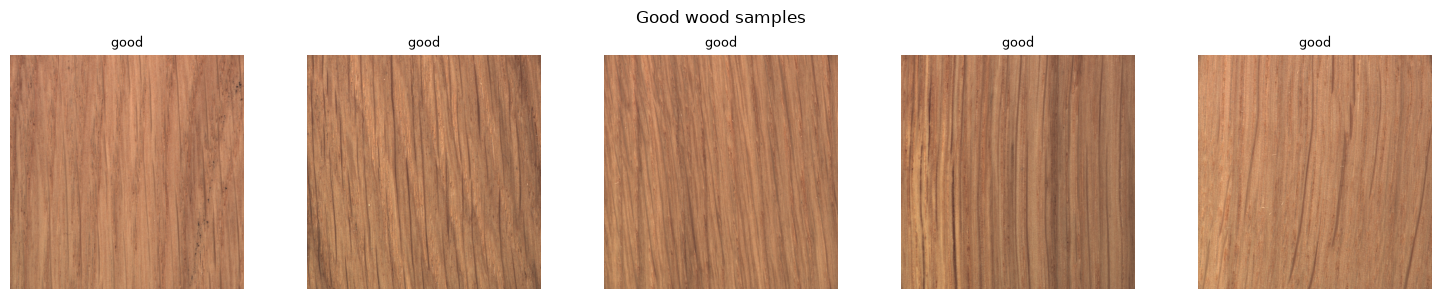

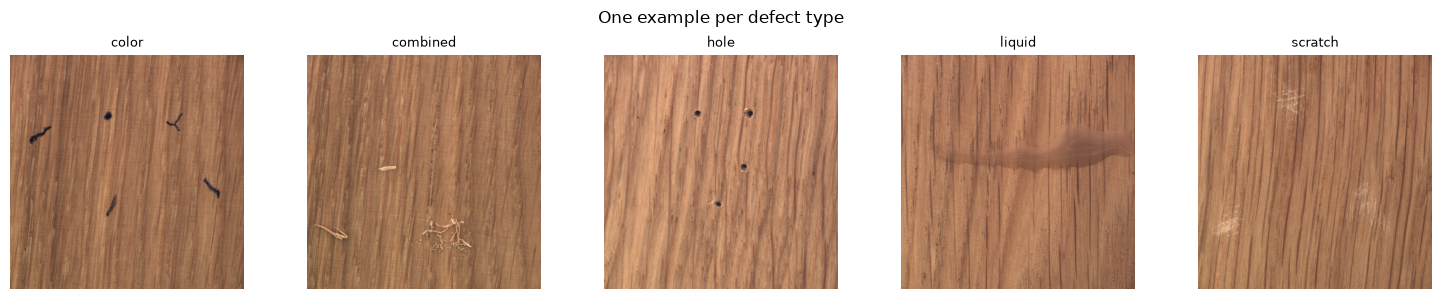

In [3]:
import random
import matplotlib.pyplot as plt

def show_images(paths, title, cols=5):
    rows = (len(paths) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    axes = axes.flatten() if rows * cols > 1 else [axes]
    for ax in axes:
        ax.axis("off")
    for ax, p in zip(axes, paths):
        ax.imshow(Image.open(p))
        ax.set_title(p.parent.name, fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

random.seed(42)

good = random.sample(list((DATA_DIR / "train" / "good").glob("*.png")), 5)
show_images(good, "Good wood samples")

defect_paths = []
for d in sorted((DATA_DIR / "test").iterdir()):
    if d.is_dir() and d.name != "good":
        defect_paths.append(random.choice(list(d.glob("*.png"))))
show_images(defect_paths, "One example per defect type")

## Observations

The dataset has 247 good training images and 60 defective test images (color 8, combined 11, hole 10, liquid 10, scratch 21), each 1024 x 1024 pixels in RGB. Good wood shows vertical grain with fairly even color, while defects range from obvious (liquid stains, dark color marks, holes) to very subtle (faint scratches and small combined marks). Because the defects are small and the dataset is imbalanced, resizing the images too much could hide them, so the input size and the train/validation/test split will matter for the model.
